# Do the post-orthogonalization steps help? Muon+ renorm + NorMuon: ON vs OFF

Compares two sweeps of the same four optimizer variants (base / MuonEq / Muon$^2$ / MuonEq + Muon$^2$):

- **post-orth ON**: `sweep_*` runs, with Muon+ Frobenius renormalization and NorMuon variance reduction (nanochat defaults).
- **post-orth OFF**: `plain_*` runs, launched with `--no-muonplus --no-normuon`.

Everything else is identical, so any gap is attributable to the two post-orthogonalization steps.

- **Plot**: val bpb vs training wall-clock, one figure per depth and one panel per variant. **Solid lines with circles = post-orth ON; dashed lines with squares = post-orth OFF.** Each run is at its own best LR (lowest final val bpb), and the panel shows the final-bpb difference.
- **Table**: time-to-target. Per (depth, variant) the target is the *worse* of the two final values, so both configs reach it; we report steps and wall-clock to first reach it, and the speedup of ON relative to OFF.
- **Fairness**: the ON sweep also covered LRs 0.005 and 0.08, which the OFF sweep did not. With `COMMON_LRS_ONLY = True` (default) both sides only choose among LRs they share.
- **Outputs**: figures (PNG + PDF) go to `<repo>/results/figures/`, tables (CSV) to `<repo>/results/tables/`, all prefixed `compare_postorth_`.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DEPTHS = [8, 12, 16]                      # depths with finished runs in BOTH sweeps are used
PREFIX = {"on": "sweep", "off": "plain"}  # run-tag prefix of each sweep
LR_MODE = "best"            # "best" = best final val bpb per (config, depth, variant); or a number like 0.02 to pin one LR for all
COMMON_LRS_ONLY = True      # only choose among LRs that finished in both sweeps (fair comparison)
REFERENCE = "off"           # baseline for the speedup column
BPB_ZOOM = 0.25             # y-range above the best final val bpb in the plots
OUT_PREFIX = "compare_postorth"

LABELS = {
    "eq":    "MuonEq",
    "eq_m2": "MuonEq + Muon$^2$",
    "m2":    "Muon$^2$",
    "base":  "Muon (no EQ, no Muon$^2$)",
}
COLORS = {"eq": "tab:blue", "eq_m2": "tab:red", "m2": "tab:green", "base": "tab:gray"}
CFG_NAME  = {"on": "post-orth ON (Muon+ & NorMuon)", "off": "post-orth OFF"}
CFG_STYLE = {"on":  dict(ls="-",  marker="o", ms=4, lw=2.0),
             "off": dict(ls="--", marker="s", ms=4, lw=1.4)}

# --- output directories: <repo root>/results/{figures,tables}; the notebook lives in <repo root>/notebooks/
def find_repo_root():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if (p / ".git").exists():
            return p
    return cwd.parent if cwd.name == "notebooks" else cwd

ROOT = find_repo_root()
FIG_DIR, TAB_DIR = ROOT / "results" / "figures", ROOT / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
print("repo root:", ROOT)

def savefig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{OUT_PREFIX}_{name}.{ext}", dpi=200, bbox_inches="tight")

def savetable(df, name, index=True):
    df.to_csv(TAB_DIR / f"{OUT_PREFIX}_{name}.csv", index=index)

repo root: /home/simon/work/courses/dsa4k/optimizer-comparison


In [2]:
STEP_RE = re.compile(r"^step (\d+)/(\d+) .*?\| loss: ([0-9.]+) .*?\| dt: ([0-9.]+)ms .*?total time: ([0-9.]+)m", re.M)
VAL_RE  = re.compile(r"^Step (\d+) \| Validation bpb: ([0-9.]+)", re.M)

# Find every logs/slurm/sweep dir at or above the cwd (the scripts may have been launched from a subdir like jobs/)
log_dirs = [p / "logs" / "slurm" / "sweep" for p in [Path.cwd(), *Path.cwd().parents]]
log_dirs = [d for d in log_dirs if d.is_dir()]
print("log dirs:", [str(d) for d in log_dirs])

def load_runs(prefix):
    """(depth, variant, lr) -> dict for every log of one sweep; if a tag has several logs keep the one with the most steps."""
    file_re = re.compile(rf"{re.escape(prefix)}_d(\d+)_(eq_m2|eq|m2|base)_lr([0-9.eE+-]+?)-(\d+)\.out$")
    runs = {}
    for d in log_dirs:
        for path in d.glob("*.out"):
            m = file_re.search(path.name)
            if not m or int(m.group(1)) not in DEPTHS:
                continue
            text = path.read_text(errors="replace")
            steps = STEP_RE.findall(text)
            if not steps:
                continue
            train = pd.DataFrame(steps, columns=["step", "n_iters", "loss", "dt_ms", "time_min"]).astype(float)
            val = pd.DataFrame(VAL_RE.findall(text), columns=["step", "val_bpb"]).astype(float)
            # wall-clock (training time only) at each eval step; the last eval comes after the final train step
            val["time_min"] = np.interp(val["step"], train["step"], train["time_min"])
            n_iters = int(train["n_iters"].iloc[0])
            mb = re.search(r"[Tt]otal batch size[^0-9]*([\d,]+)", text)   # tokens per optimizer step (NaN if not found)
            batch_tokens = int(mb.group(1).replace(",", "")) if mb else np.nan
            key = (int(m.group(1)), m.group(2), float(m.group(3)))
            if key not in runs or len(train) > len(runs[key]["train"]):
                runs[key] = dict(train=train, val=val, path=path, n_iters=n_iters, batch_tokens=batch_tokens,
                                 finished=len(train) >= n_iters and len(val) > 0)
    return runs

RUNS = {cfg: load_runs(PREFIX[cfg]) for cfg in ("on", "off")}

rows = []
for cfg, runs in RUNS.items():
    for (depth, v, lr), r in sorted(runs.items()):
        rows.append(dict(post_orth=cfg, depth=depth, variant=v, lr=lr, finished=r["finished"],
                         final_val_bpb=r["val"]["val_bpb"].iloc[-1] if len(r["val"]) else np.nan,
                         final_train_loss=r["train"]["loss"].iloc[-1],
                         train_min=r["train"]["time_min"].iloc[-1]))
summary = pd.DataFrame(rows)
if summary.empty:
    avail = []
else:
    fin = summary[summary.finished]
    on_d, off_d = set(fin[fin.post_orth == "on"].depth), set(fin[fin.post_orth == "off"].depth)
    avail = sorted(on_d & off_d)
print("finished runs per (config, depth):", fin.groupby(["post_orth", "depth"]).size().to_dict() if len(summary) else {})
print("depths finished in BOTH sweeps:", avail)
summary

log dirs: ['/home/simon/work/courses/dsa4k/optimizer-comparison/logs/slurm/sweep']
finished runs per (config, depth): {('off', 8): 12, ('off', 12): 12, ('on', 8): 20, ('on', 12): 20, ('on', 16): 20}
depths finished in BOTH sweeps: [8, 12]


,post_orth,depth,variant,lr,finished,final_val_bpb,final_train_loss,train_min
0,on,8,base,0.005,True,0.966126,3.179370,14.42
1,on,8,base,0.010,True,0.946256,3.113984,15.51
2,on,8,base,0.020,True,0.943899,3.106512,15.51
3,on,8,base,0.040,True,0.947393,3.118509,15.52
4,on,8,base,0.080,True,0.955785,3.146774,18.13
...,...,...,...,...,...,...,...,...
79,off,12,eq_m2,0.020,True,0.849767,2.817869,119.95
80,off,12,eq_m2,0.040,True,0.850388,2.819320,84.04
81,off,12,m2,0.010,True,0.852104,2.824877,90.80
82,off,12,m2,0.020,True,0.848373,2.812867,102.94


In [3]:
# Pick one LR per (config, depth, variant)
chosen = {}
for depth in avail:
    for v in LABELS:
        f = {cfg: fin[(fin.post_orth == cfg) & (fin.depth == depth) & (fin.variant == v)] for cfg in ("on", "off")}
        if f["on"].empty or f["off"].empty:
            print(f"d{depth}: {v} is missing finished runs in one of the sweeps, skipping"); continue
        if COMMON_LRS_ONLY:
            common = set(f["on"].lr) & set(f["off"].lr)
            f = {cfg: df[df.lr.isin(common)] for cfg, df in f.items()}
        for cfg, df in f.items():
            if df.empty:
                continue
            if LR_MODE == "best":
                chosen[(cfg, depth, v)] = df.loc[df.final_val_bpb.idxmin(), "lr"]
            elif float(LR_MODE) in set(df.lr):
                chosen[(cfg, depth, v)] = float(LR_MODE)
            else:
                print(f"d{depth}: {v} ({cfg}) has no finished run at lr={LR_MODE}")

sel = summary[summary.apply(lambda r: chosen.get((r.post_orth, r.depth, r.variant)) == r.lr, axis=1)]
sel_table = sel.set_index(["depth", "variant", "post_orth"]).sort_index()
if len(sel_table):
    savetable(sel_table, "selected_runs")
sel_table

lr  finished  final_val_bpb  final_train_loss  \
depth variant post_orth                                                    
8     base    off        0.02      True       0.946592          3.115944   
              on         0.02      True       0.943899          3.106512   
      eq      off        0.02      True       0.942539          3.103473   
              on         0.02      True       0.944423          3.109243   
      eq_m2   off        0.02      True       0.945090          3.111477   
              on         0.02      True       0.946092          3.114883   
      m2      off        0.02      True       0.945272          3.112412   
              on         0.02      True       0.947244          3.118749   
12    base    off        0.04      True       0.853379          2.830154   
              on         0.02      True       0.848447          2.813136   
      eq      off        0.02      True       0.847155          2.807869   
              on         0.02      True       0.847100          2.808979   
      eq_m2   off        0.02      True       0.849767          2.817869   
              on         0.02      True       0.848110          2.811612   
      m2      off        0.02      True       0.848373          2.812867   
              on         0.02      True       0.847765          2.811447   

                         train_min  
depth variant post_orth             
8     base    off            18.84  
              on             15.51  
      eq      off            14.47  
              on             16.74  
      eq_m2   off            16.35  
              on             15.53  
      m2      off            14.41  
              on             10.52  
12    base    off            99.54  
              on             81.73  
      eq      off            89.60  
              on             89.47  
      eq_m2   off           119.95  
              on             94.67  
      m2      off           102.94  
              on             94.92

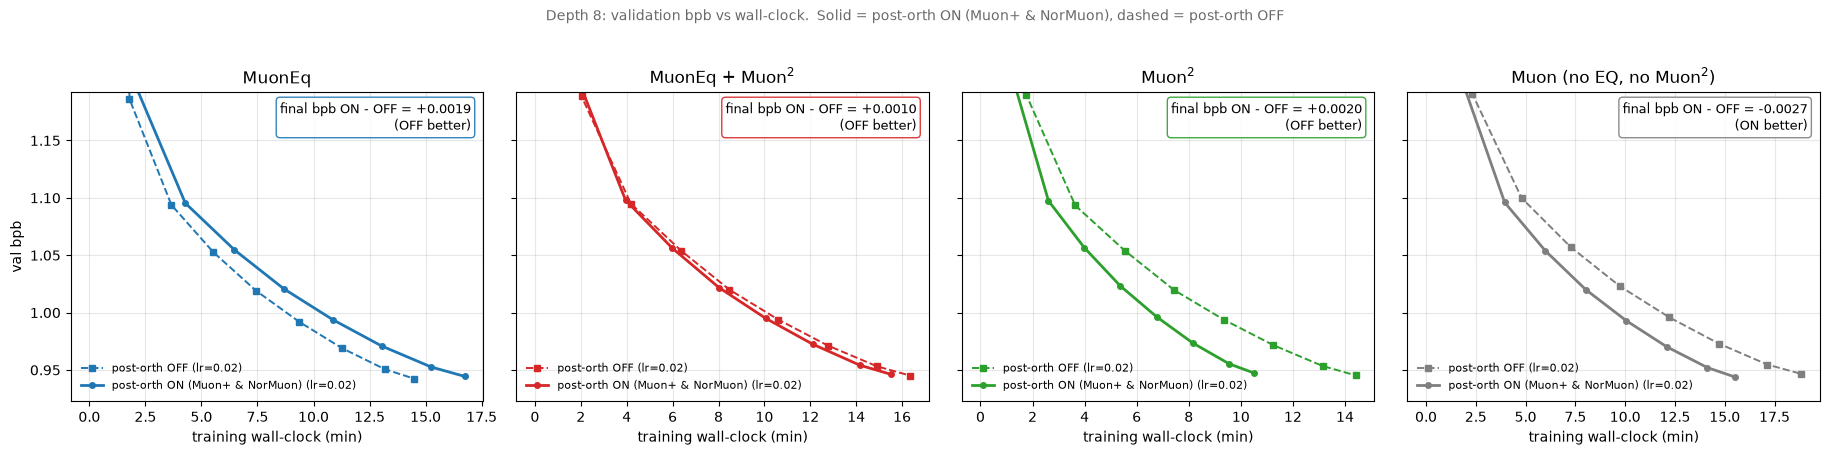

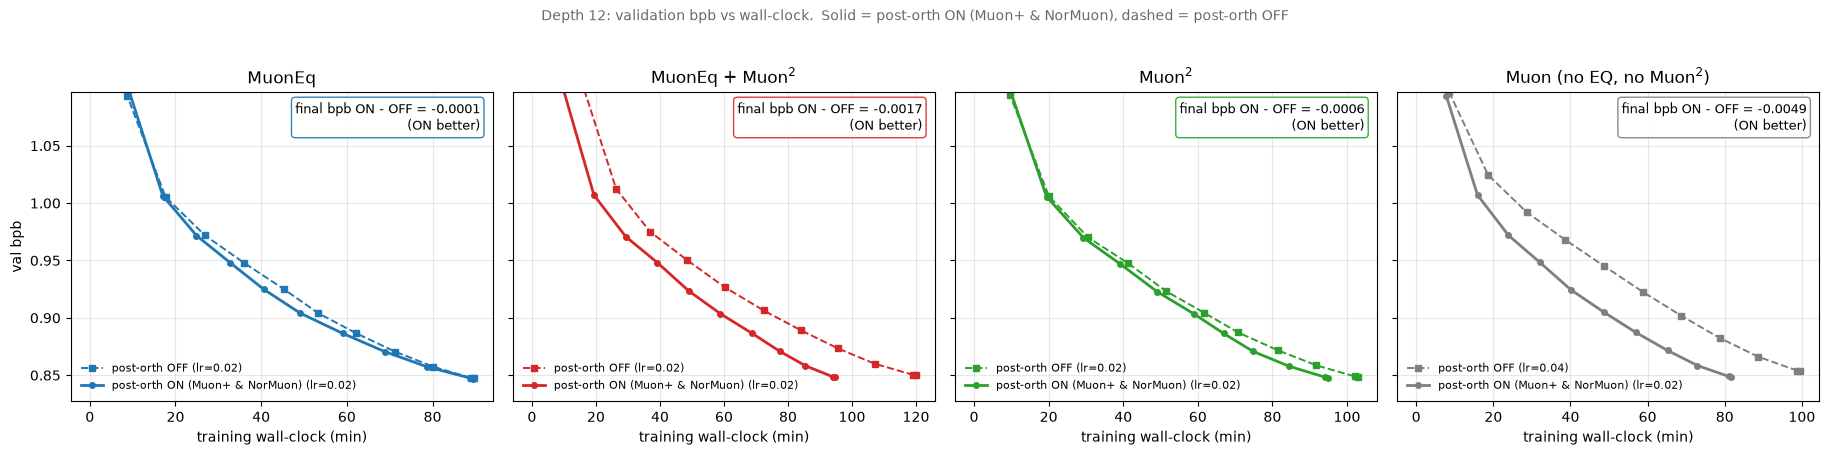

In [7]:
# Validation bpb vs training wall-clock. One figure per depth, one panel per variant.
# Solid + circles = post-orth ON, dashed + squares = post-orth OFF.
def plot_val_bpb_wallclock(depth):
    vs = [v for v in LABELS if ("on", depth, v) in chosen and ("off", depth, v) in chosen]
    if not vs:
        return
    fig, axes = plt.subplots(1, len(vs), figsize=(4.6 * len(vs), 4.6), squeeze=False, sharey=True)
    finals = []
    for ax, v in zip(axes[0], vs):
        f = {}
        for cfg in ("off", "on"):    # draw OFF first so the ON line sits on top
            lr = chosen[(cfg, depth, v)]
            val = RUNS[cfg][(depth, v, lr)]["val"]
            f[cfg] = val["val_bpb"].iloc[-1]
            ax.plot(val["time_min"], val["val_bpb"], color=COLORS[v], label=f"{CFG_NAME[cfg]} (lr={lr:g})", **CFG_STYLE[cfg])
        finals += list(f.values())
        d = f["on"] - f["off"]
        ax.text(0.97, 0.97, f"final bpb ON - OFF = {d:+.4f}\n({'ON better' if d < 0 else 'OFF better'})",
                transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(boxstyle="round", fc="white", ec=COLORS[v], alpha=0.9))
        ax.set_title(LABELS[v])
        ax.set_xlabel("training wall-clock (min)")
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=8, loc="lower left")
    axes[0][0].set_ylabel("val bpb")
    axes[0][0].set_ylim(min(finals) - 0.02, min(finals) + BPB_ZOOM)
    fig.suptitle(f"Depth {depth}: validation bpb vs wall-clock.  Solid = post-orth ON (Muon+ & NorMuon), dashed = post-orth OFF",
                 fontsize=10, color="dimgray")
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    savefig(fig, f"d{depth}_val_bpb_vs_wallclock")
    plt.show()

for depth in avail:
    plot_val_bpb_wallclock(depth)

## Time-to-target

For each (depth, variant), the **target is a constant: the worse (higher) of the two final values**, ON vs OFF, each run at its selected LR, so both configs reach it by the end of their runs. We report the first step and wall-clock minute at which each config reaches the target (linear interpolation between logged points; validation bpb is only logged every `--eval-every` steps, the smoothed train loss every step).

**Speedup** follows the Muon+ paper convention, `T_ref / T - 1` in %, separately for steps and wall-clock, with `REFERENCE = "off"` as the baseline. So a positive number on an ON row means the post-orthogonalization steps reach the target faster than without them; the OFF row is 0 by construction. Tokens = steps × the total batch size parsed from the log (NaN if that line isn't found). Wall-clock speedups are only meaningful if both sweeps ran on the same GPU type per depth.

In [5]:
TARGET_METRICS = {"val_bpb": "val bpb", "loss": "train loss (EMA)"}

def metric_series(r, metric):
    d = r["val"] if metric == "val_bpb" else r["train"]
    return d["step"].to_numpy(), d["time_min"].to_numpy(), d[metric].to_numpy()

def first_crossing(steps, times, y, target):
    """First (step, minute) at which y <= target, linearly interpolated; NaN if never reached."""
    idx = np.flatnonzero(y <= target)
    if len(idx) == 0:
        return np.nan, np.nan
    i = idx[0]
    if i == 0:
        return steps[0], times[0]
    f = (y[i - 1] - target) / (y[i - 1] - y[i])
    return steps[i - 1] + f * (steps[i] - steps[i - 1]), times[i - 1] + f * (times[i] - times[i - 1])

rows = []
for depth in avail:
    for v in LABELS:
        if ("on", depth, v) not in chosen or ("off", depth, v) not in chosen:
            continue
        r = {cfg: RUNS[cfg][(depth, v, chosen[(cfg, depth, v)])] for cfg in ("on", "off")}
        for metric, mname in TARGET_METRICS.items():
            finals = {cfg: metric_series(r[cfg], metric)[2][-1] for cfg in r}
            worst = max(finals, key=finals.get)
            target = finals[worst]
            res = {}
            for cfg in r:
                st, tm = first_crossing(*metric_series(r[cfg], metric), target)
                res[cfg] = dict(steps=st, minutes=tm, tokens_M=st * r[cfg]["batch_tokens"] / 1e6)
            for cfg in ("on", "off"):
                rows.append(dict(
                    depth=depth, variant=v, metric=mname, post_orth=cfg.upper(), lr=chosen[(cfg, depth, v)],
                    final=finals[cfg], target=target, target_set_by=worst.upper(),
                    steps_to_target=res[cfg]["steps"], tokens_M=res[cfg]["tokens_M"], minutes_to_target=res[cfg]["minutes"],
                    speedup_steps_pct=(res[REFERENCE]["steps"] / res[cfg]["steps"] - 1) * 100,
                    speedup_time_pct=(res[REFERENCE]["minutes"] / res[cfg]["minutes"] - 1) * 100,
                ))

ttt = pd.DataFrame(rows)
if ttt.empty:
    print("need finished runs in both sweeps at the same depth")
else:
    ttt = ttt.round({"final": 4, "target": 4, "steps_to_target": 0, "tokens_M": 1, "minutes_to_target": 2,
                     "speedup_steps_pct": 1, "speedup_time_pct": 1})
    savetable(ttt, "time_to_target", index=False)
    print(f"speedups of ON (Muon+ & NorMuon) relative to {REFERENCE.upper()}; positive = ON reaches the target faster")
    display(ttt.set_index(["depth", "metric", "variant", "post_orth"]))

speedups of ON (Muon+ & NorMuon) relative to OFF; positive = ON reaches the target faster


lr   final  target target_set_by  \
depth metric           variant post_orth                                       
8     val bpb          eq      ON         0.02  0.9444  0.9444            ON   
                               OFF        0.02  0.9425  0.9444            ON   
      train loss (EMA) eq      ON         0.02  3.1092  3.1092            ON   
                               OFF        0.02  3.1035  3.1092            ON   
      val bpb          eq_m2   ON         0.02  0.9461  0.9461            ON   
                               OFF        0.02  0.9451  0.9461            ON   
      train loss (EMA) eq_m2   ON         0.02  3.1149  3.1149            ON   
                               OFF        0.02  3.1115  3.1149            ON   
      val bpb          m2      ON         0.02  0.9472  0.9472            ON   
                               OFF        0.02  0.9453  0.9472            ON   
      train loss (EMA) m2      ON         0.02  3.1187  3.1187            ON   
                               OFF        0.02  3.1124  3.1187            ON   
      val bpb          base    ON         0.02  0.9439  0.9466           OFF   
                               OFF        0.02  0.9466  0.9466           OFF   
      train loss (EMA) base    ON         0.02  3.1065  3.1159           OFF   
                               OFF        0.02  3.1159  3.1159           OFF   
12    val bpb          eq      ON         0.02  0.8471  0.8472           OFF   
                               OFF        0.02  0.8472  0.8472           OFF   
      train loss (EMA) eq      ON         0.02  2.8090  2.8090            ON   
                               OFF        0.02  2.8079  2.8090            ON   
      val bpb          eq_m2   ON         0.02  0.8481  0.8498           OFF   
                               OFF        0.02  0.8498  0.8498           OFF   
      train loss (EMA) eq_m2   ON         0.02  2.8116  2.8179           OFF   
                               OFF        0.02  2.8179  2.8179           OFF   
      val bpb          m2      ON         0.02  0.8478  0.8484           OFF   
                               OFF        0.02  0.8484  0.8484           OFF   
      train loss (EMA) m2      ON         0.02  2.8114  2.8129           OFF   
                               OFF        0.02  2.8129  2.8129           OFF   
      val bpb          base    ON         0.02  0.8484  0.8534           OFF   
                               OFF        0.04  0.8534  0.8534           OFF   
      train loss (EMA) base    ON         0.02  2.8131  2.8302           OFF   
                               OFF        0.04  2.8302  2.8302           OFF   

                                          steps_to_target  tokens_M  \
depth metric           variant post_orth                              
8     val bpb          eq      ON                  1920.0     503.3   
                               OFF                 1881.0     493.1   
      train loss (EMA) eq      ON                  1730.0     453.6   
                               OFF                 1694.0     444.0   
      val bpb          eq_m2   ON                  1920.0     503.3   
                               OFF                 1899.0     497.8   
      train loss (EMA) eq_m2   ON                  1730.0     453.6   
                               OFF                 1694.0     444.0   
      val bpb          m2      ON                  1920.0     503.3   
                               OFF                 1879.0     492.6   
      train loss (EMA) m2      ON                  1694.0     444.1   
                               OFF                 1694.0     444.0   
      val bpb          base    ON                  1864.0     488.6   
                               OFF                 1920.0     503.3   
      train loss (EMA) base    ON                  1694.0     444.0   
                               OFF                 1694.0     444.1   
12    val bpb          eq      ON            